In [1]:
from IPython.display import HTML, display

display(HTML("""
<style>
@page { size: A4 portrait; margin: 7mm 9mm; }
@page q2land { size: A4 landscape; margin: 7mm 10mm; }
.jp-RenderedHTMLCommon pre { background: #f1f1f1 !important; border: 1px solid #d2d2d2 !important; border-radius: 3px !important; padding: 3pt 4pt !important; }
@media print {
  html, body { font-family: Arial, sans-serif !important; font-size: 8.1pt !important; line-height: 1.08 !important; color: #111 !important; }
  h1 { font-size: 15pt !important; margin: 0 0 3pt !important; }
  h2 { font-size: 11pt !important; margin: 4pt 0 2pt !important; }
  h3 { font-size: 8.7pt !important; margin: 3pt 0 1pt !important; }
  p, ul, ol, table { margin: 1.5pt 0 !important; }
  table { font-size: 7pt !important; border-collapse: collapse !important; }
  th, td { padding: 1.5pt 3pt !important; }
  pre, code { font-family: Consolas, monospace !important; font-size: 7.1pt !important; line-height: 1.03 !important; }
  pre { white-space: pre-wrap !important; margin: 1pt 0 !important; background: #f1f1f1 !important; border: 1px solid #d2d2d2 !important; border-radius: 3px !important; padding: 3pt 4pt !important; -webkit-print-color-adjust: exact !important; print-color-adjust: exact !important; }
  .cell { padding: .5pt 0 !important; margin: 0 !important; }
  .celltag_hide_input .jp-Cell-inputWrapper { display: none !important; }
  .celltag_pagebreak { break-before: page !important; }
  .celltag_q2_landscape { page: q2land; break-before: page !important; }
  .figure-grid { display: grid !important; grid-template-columns: 1fr 1fr !important; gap: 3mm 5mm !important; align-items: center !important; }
  .figure-grid figure { margin: 0 !important; padding: 0 !important; break-inside: avoid !important; text-align: center !important; }
  .figure-grid img { width: auto !important; max-width: 100% !important; height: auto !important; object-fit: contain !important; }
  .q1-chart img { width: 100% !important; max-height: 2.05in !important; }
  .q2-grid .curve img { max-height: 1.9in !important; }
  .q2-grid .matrix img { max-height: 4.4in !important; }
  .q2-grid figure:nth-of-type(1) { grid-column: 1; grid-row: 1; }
  .q2-grid figure:nth-of-type(2) { grid-column: 2; grid-row: 1; }
  .q2-grid figure:nth-of-type(3) { grid-column: 1; grid-row: 2; }
  .q2-grid figure:nth-of-type(4) { grid-column: 2; grid-row: 2; }
  .q3-grid .curve img { max-height: 1.45in !important; }
  .q3-grid .matrix img { max-height: 2.35in !important; }
  .q3-grid figure:nth-of-type(1) { grid-column: 1; grid-row: 1; }
  .q3-grid figure:nth-of-type(2) { grid-column: 2; grid-row: 1; }
  .q3-grid figure:nth-of-type(3) { grid-column: 1; grid-row: 2; }
  .q3-grid figure:nth-of-type(4) { grid-column: 2; grid-row: 2; }
  figcaption { font-size: 6.5pt !important; margin-top: 1pt !important; }
  h1, h2, h3 { break-after: avoid !important; }
}
</style>
"""))

# EN3160 Assignment 3: Neural Networks

**H.D.J.D.Samaranayaka** | **230563H** | GitHub: https://github.com/jaindusamaranayaka/EN3160-Neural-Networks.git | PDF: `230563H_a02.pdf`

The notebook includes the required code excerpts, saved outputs, comparisons, and discussion. Run All loads saved results; it does not retrain unless `RUN_TRAINING` is changed to `True`.

In [2]:
import base64
import json
import os
import subprocess
import sys
from pathlib import Path
from IPython.display import HTML, Markdown, display


def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")

PROJECT_ROOT = find_project_root()
ENV = os.environ.copy()
ENV["PYTHONPATH"] = str(PROJECT_ROOT) + os.pathsep + ENV.get("PYTHONPATH", "")
RUN_TRAINING = False


def run_module(module, *args):
    subprocess.run([sys.executable, "-m", module, *args], cwd=PROJECT_ROOT, env=ENV, check=True)


def image_data(path):
    encoded = base64.b64encode(Path(path).read_bytes()).decode("ascii")
    return f"data:image/png;base64,{encoded}"


def show_chart(path, alt):
    display(HTML(f'<div class="q1-chart"><img alt="{alt}" src="{image_data(path)}"></div>'))


def show_grid(items, css_class):
    figures = "".join(
        f'<figure class="{kind}"><img alt="{caption}" src="{image_data(path)}">'
        f'<figcaption>{caption}</figcaption></figure>'
        for path, caption, kind in items
    )
    display(HTML(f'<div class="figure-grid {css_class}">{figures}</div>'))

## Question 1 - CIFAR-10 manual backpropagation

Use the Listing 1 CIFAR-10 input pipeline: 32 x 32 RGB images, tensor conversion, per-channel normalization to [-1, 1], batch size 50, shuffled training batches, and 10 epochs. The baseline keeps Listing 1 single linear layer; both models use cross-entropy and the same SGD setup (learning rate 0.01, momentum 0.9) to isolate the effect of the added hidden layer.

```python
transform = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize((.5,)*3, (.5,)*3)])
train = datasets.CIFAR10("data", train=True, download=True, transform=transform)
test  = datasets.CIFAR10("data", train=False, download=True, transform=transform)
train_loader = DataLoader(train, batch_size=50, shuffle=True)
test_loader  = DataLoader(test, batch_size=50, shuffle=False)
```

### Manual forward pass and backpropagation

The gradients below are computed directly; the Q1 training path does not use `nn.Linear`, `loss.backward()`, or autograd. `cross_entropy` is used to report the loss, while the displayed derivatives drive the parameter updates.

```python
x = x.reshape(x.size(0), -1)                  # N x 3072
h = torch.sigmoid(x @ W1 + b1)                # N x 100
logits = h @ W2 + b2                          # N x 10
loss = F.cross_entropy(logits, labels)  # report only
one_hot = F.one_hot(labels, num_classes=10).to(logits.dtype)
dlogits = (logits.softmax(1) - one_hot) / len(labels)
dW2, db2 = h.T @ dlogits, dlogits.sum(0)
dh = dlogits @ W2.T
dz = dh * h * (1 - h)
dW1, db1 = x.T @ dz, dz.sum(0)
# Manual momentum-SGD update for each weight and bias
velocity = momentum * velocity + gradient
parameter -= learning_rate * velocity
```

Weights and biases are initialized in `src/dense_network/train.py`; the script trains both the linear baseline and the 100-unit sigmoid model and saves the per-epoch training-loss comparison.

| Model | Train accuracy | Test accuracy | Test loss |
|---|---:|---:|---:|
| Listing 1 linear baseline | 39.69% | 34.89% | 2.0540 |
| 100-unit sigmoid | 55.14% | 47.86% | 1.5077 |


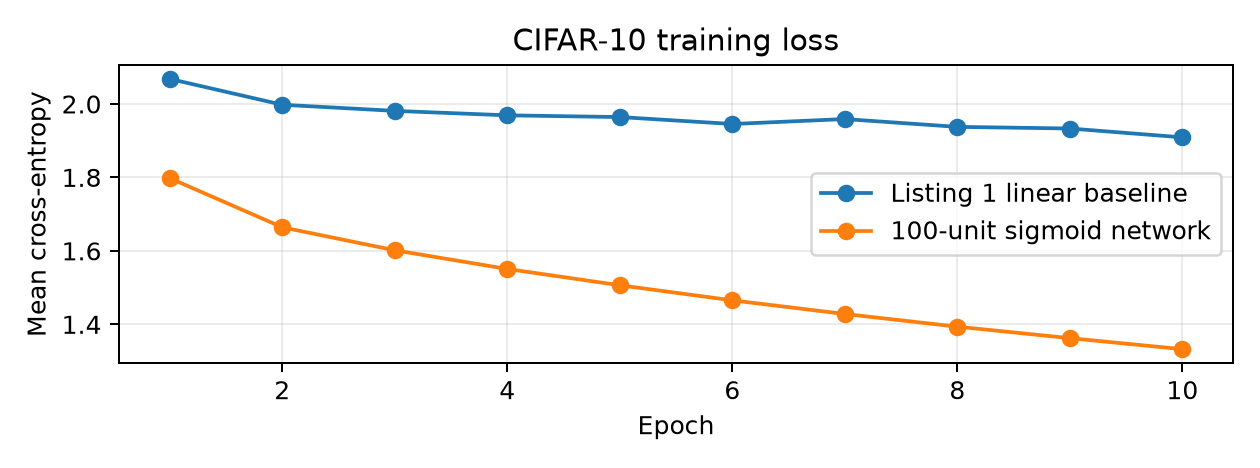

In [3]:
if RUN_TRAINING:
    run_module("src.dense_network.train", "--epochs", "10", "--data", str(PROJECT_ROOT / "data"))

baseline = json.loads((PROJECT_ROOT / "reports/cifar10_linear_baseline_history.json").read_text())
manual = json.loads((PROJECT_ROOT / "reports/cifar10_dense_history.json").read_text())
rows = "\n".join(
    f"| {label} | {item['train_accuracy'][-1]:.2%} | {item['test_accuracy'][-1]:.2%} | {item['test_loss'][-1]:.4f} |"
    for label, item in (("Listing 1 linear baseline", baseline), ("100-unit sigmoid", manual)))
display(Markdown("| Model | Train accuracy | Test accuracy | Test loss |\n|---|---:|---:|---:|\n" + rows))
show_chart(PROJECT_ROOT / "outputs/figures/cifar10_manual_training_loss.png",
           "CIFAR-10 training loss for the linear baseline and manual sigmoid network")

The hidden-layer model improves test accuracy over the matched one-layer baseline, but 47.86% test accuracy and 55.14% training accuracy still indicate underfitting on CIFAR-10. Compared with the linear baseline, the manual 100-unit model improves test accuracy from 34.89% to 47.86%. Flattening discards spatial layout, limiting the dense model's ability to learn local image features.

## Question 2 - MNIST CNNs

Both models use the same MNIST split, 10 epochs, batch size 64, learning rate 0.01, SGD with momentum 0.9, and normalization with the dataset mean and standard deviation. No image augmentation is applied.

```python
transform = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])
train = datasets.MNIST("data", train=True, download=True, transform=transform)
test  = datasets.MNIST("data", train=False, download=True, transform=transform)
train_loader = DataLoader(train, batch_size=64, shuffle=True)
test_loader  = DataLoader(test, batch_size=64, shuffle=False)
# fit(..., epochs=10, learning_rate=0.01, device=device)
```

LeNet-5 is implemented as a LeNet-style variant using ReLU and max-pooling (the original uses tanh and average-pooling). The second model has three convolutional layers with batch normalization and dropout.

```python
lenet = nn.Sequential(
    nn.Conv2d(1,6,5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6,16,5), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
    nn.Linear(256,120), nn.ReLU(), nn.Linear(120,84), nn.ReLU(), nn.Linear(84,10))
small_cnn = nn.Sequential(
    nn.Conv2d(1,16,3,padding=1), nn.BatchNorm2d(16), nn.ReLU(),
    nn.Conv2d(16,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
    nn.Dropout(.25), nn.Flatten(), nn.Linear(3136,128), nn.ReLU(),
    nn.Dropout(.5), nn.Linear(128,10))
```

### Shared PyTorch training loop

The scripts use cross-entropy with SGD and momentum. Training accuracy is the sample-weighted running score while the model is in training mode; test accuracy is measured after the epoch with `model.eval()`. Dropout and this online metric both contribute to test accuracy being higher than training accuracy for the small CNN. For a frozen ResNet, frozen BatchNorm layers are also kept in evaluation mode so their running statistics do not change.

```python
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
for epoch in range(epochs):
    model.train(); train_correct = train_total = 0
    # Keep BatchNorm running statistics fixed in the frozen ResNet.
    for layer in model.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm) and not any(
            p.requires_grad for p in layer.parameters(recurse=False)):
            layer.eval()
    for x, y in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(x.to(device)); loss = criterion(logits, y.to(device))
        loss.backward()                         # Q2/Q3 use PyTorch autograd
        optimizer.step()
        train_correct += logits.argmax(1).eq(y.to(device)).sum().item(); train_total += len(y)
    train_accuracy = train_correct / train_total
    model.eval(); correct = total = 0
    with torch.inference_mode():
        for x_test, y_test in test_loader:
            pred = model(x_test.to(device)).argmax(1)
            correct += pred.eq(y_test.to(device)).sum().item(); total += len(y_test)
    test_accuracy = correct / total
```

### Confusion-matrix calculation and plot

```python
from sklearn.metrics import confusion_matrix
import numpy as np
cm = confusion_matrix(targets, predictions, labels=range(10))
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Blues", interpolation="nearest")
for row, col in np.ndindex(cm.shape):
    ax.text(col, row, str(cm[row, col]), ha="center", va="center")
ax.set(xlabel="Predicted label", ylabel="True label")
fig.tight_layout(); fig.savefig(path, dpi=220)
```

The saved matrices print their cell counts in larger type. The plotted loss and accuracy traces are included with the matrices on the next page.

### MNIST results

| Model | Train accuracy | Test accuracy | Test loss |
|---|---:|---:|---:|
| LeNet-style (ReLU/max-pool) | 99.52% | 99.09% | 0.0293 |
| Three-layer CNN | 98.92% | 99.31% | 0.0214 |

LeNet's most frequent error is 3 -> 5 (7 cases); the small CNN's is 6 -> 0 (9 cases). The test-accuracy difference is 0.22 percentage points, about 22 images out of 10,000. Since this is one seed and one run, it does not establish a reliable winner.


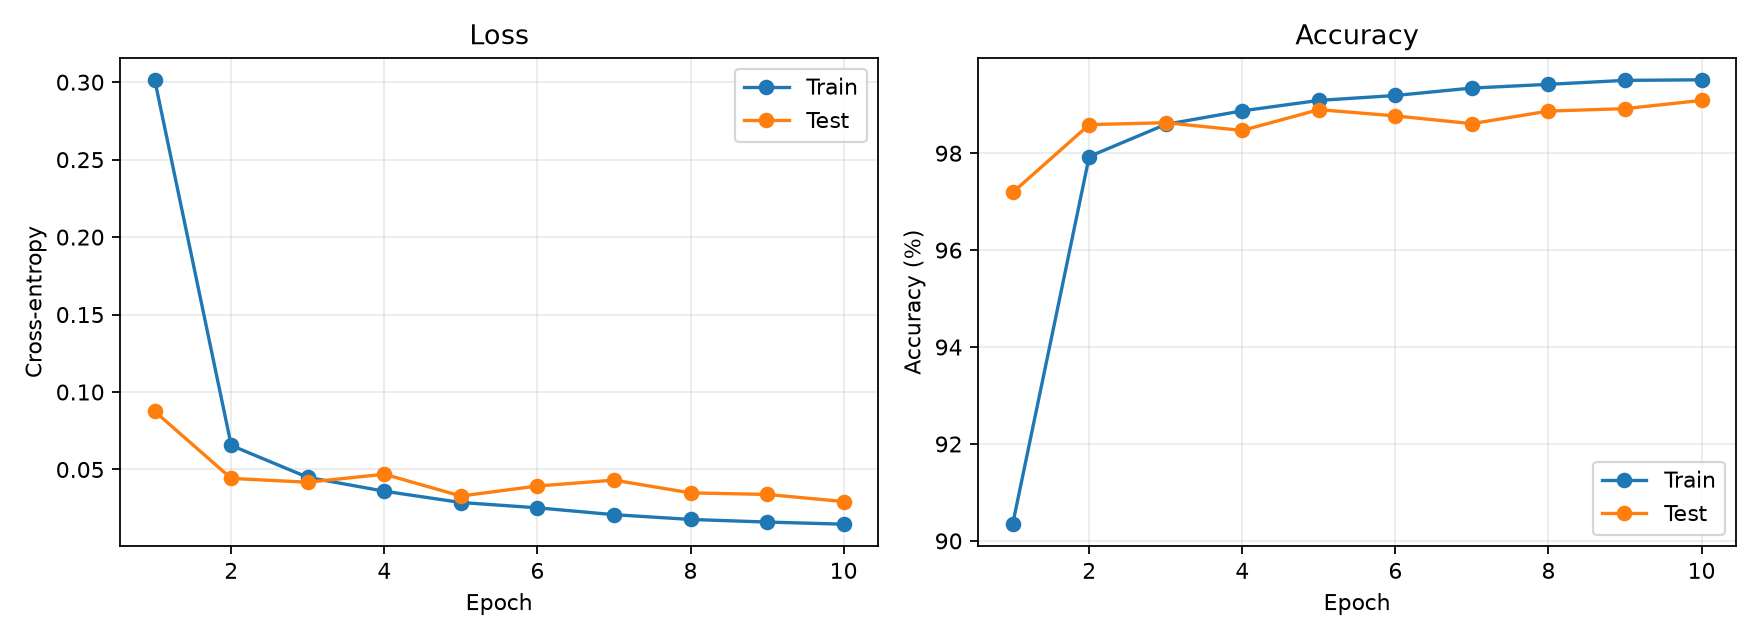
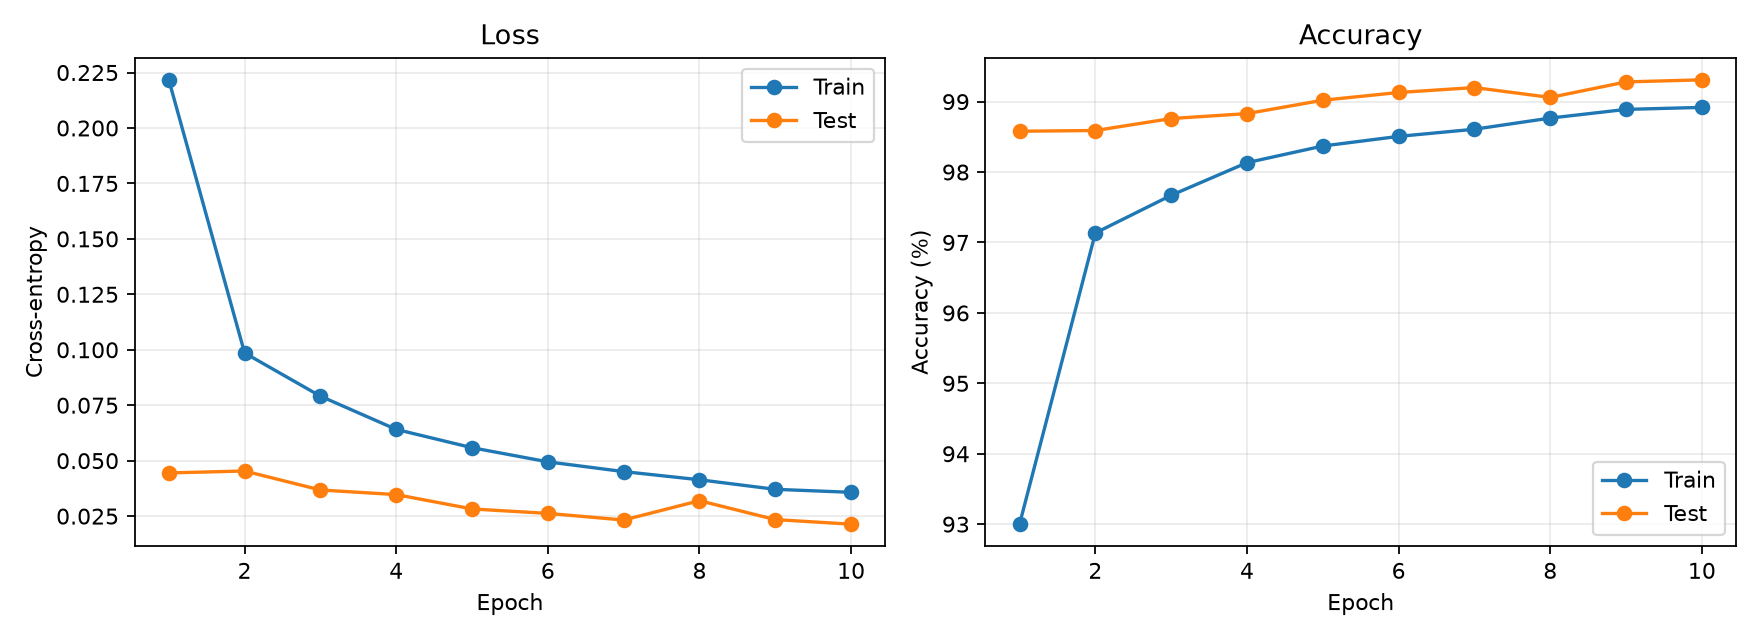
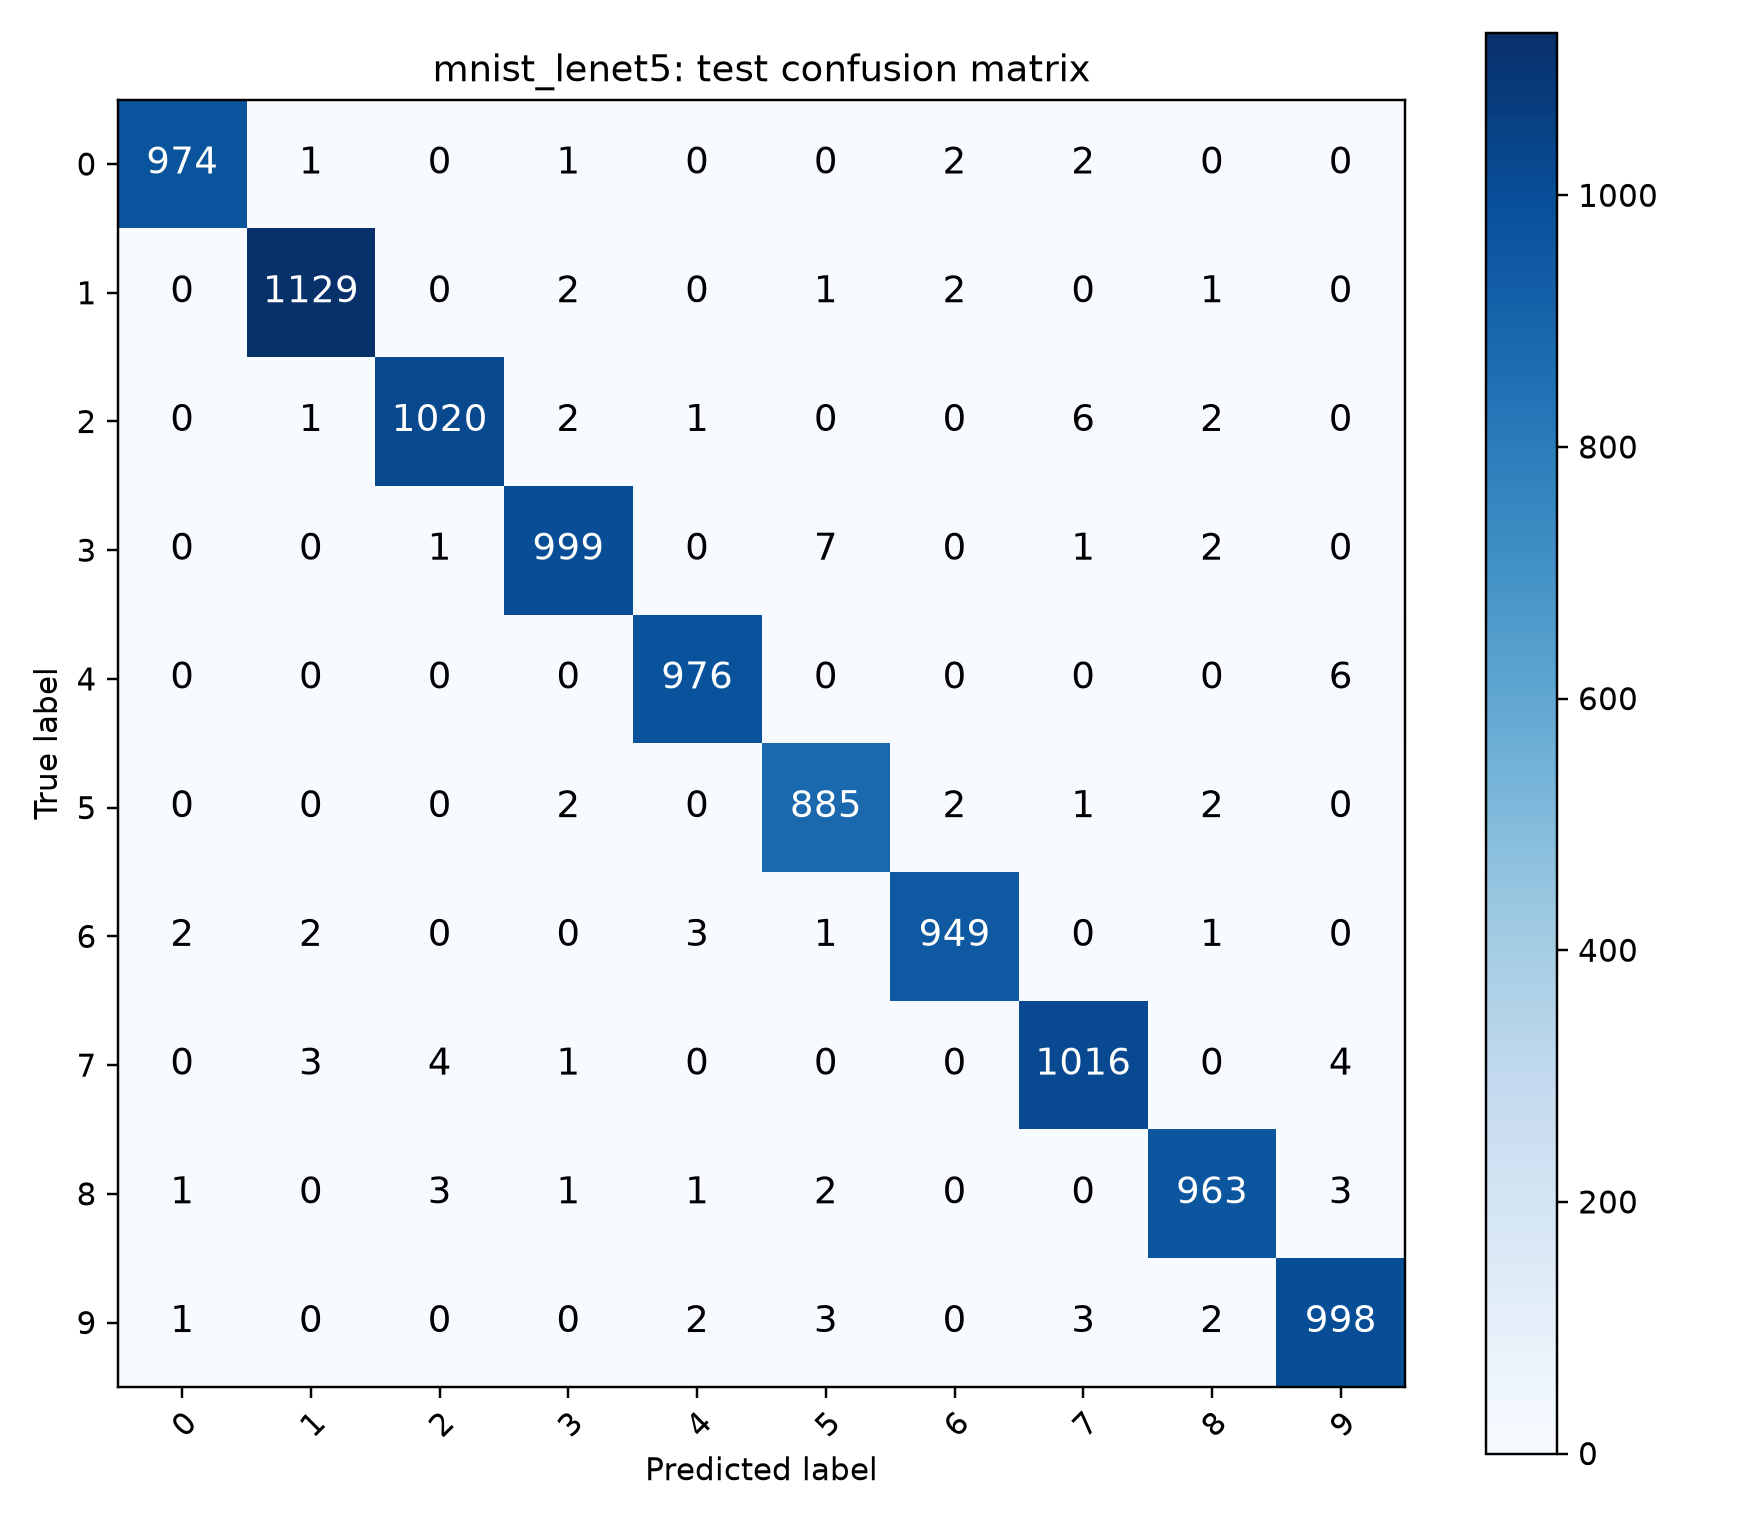
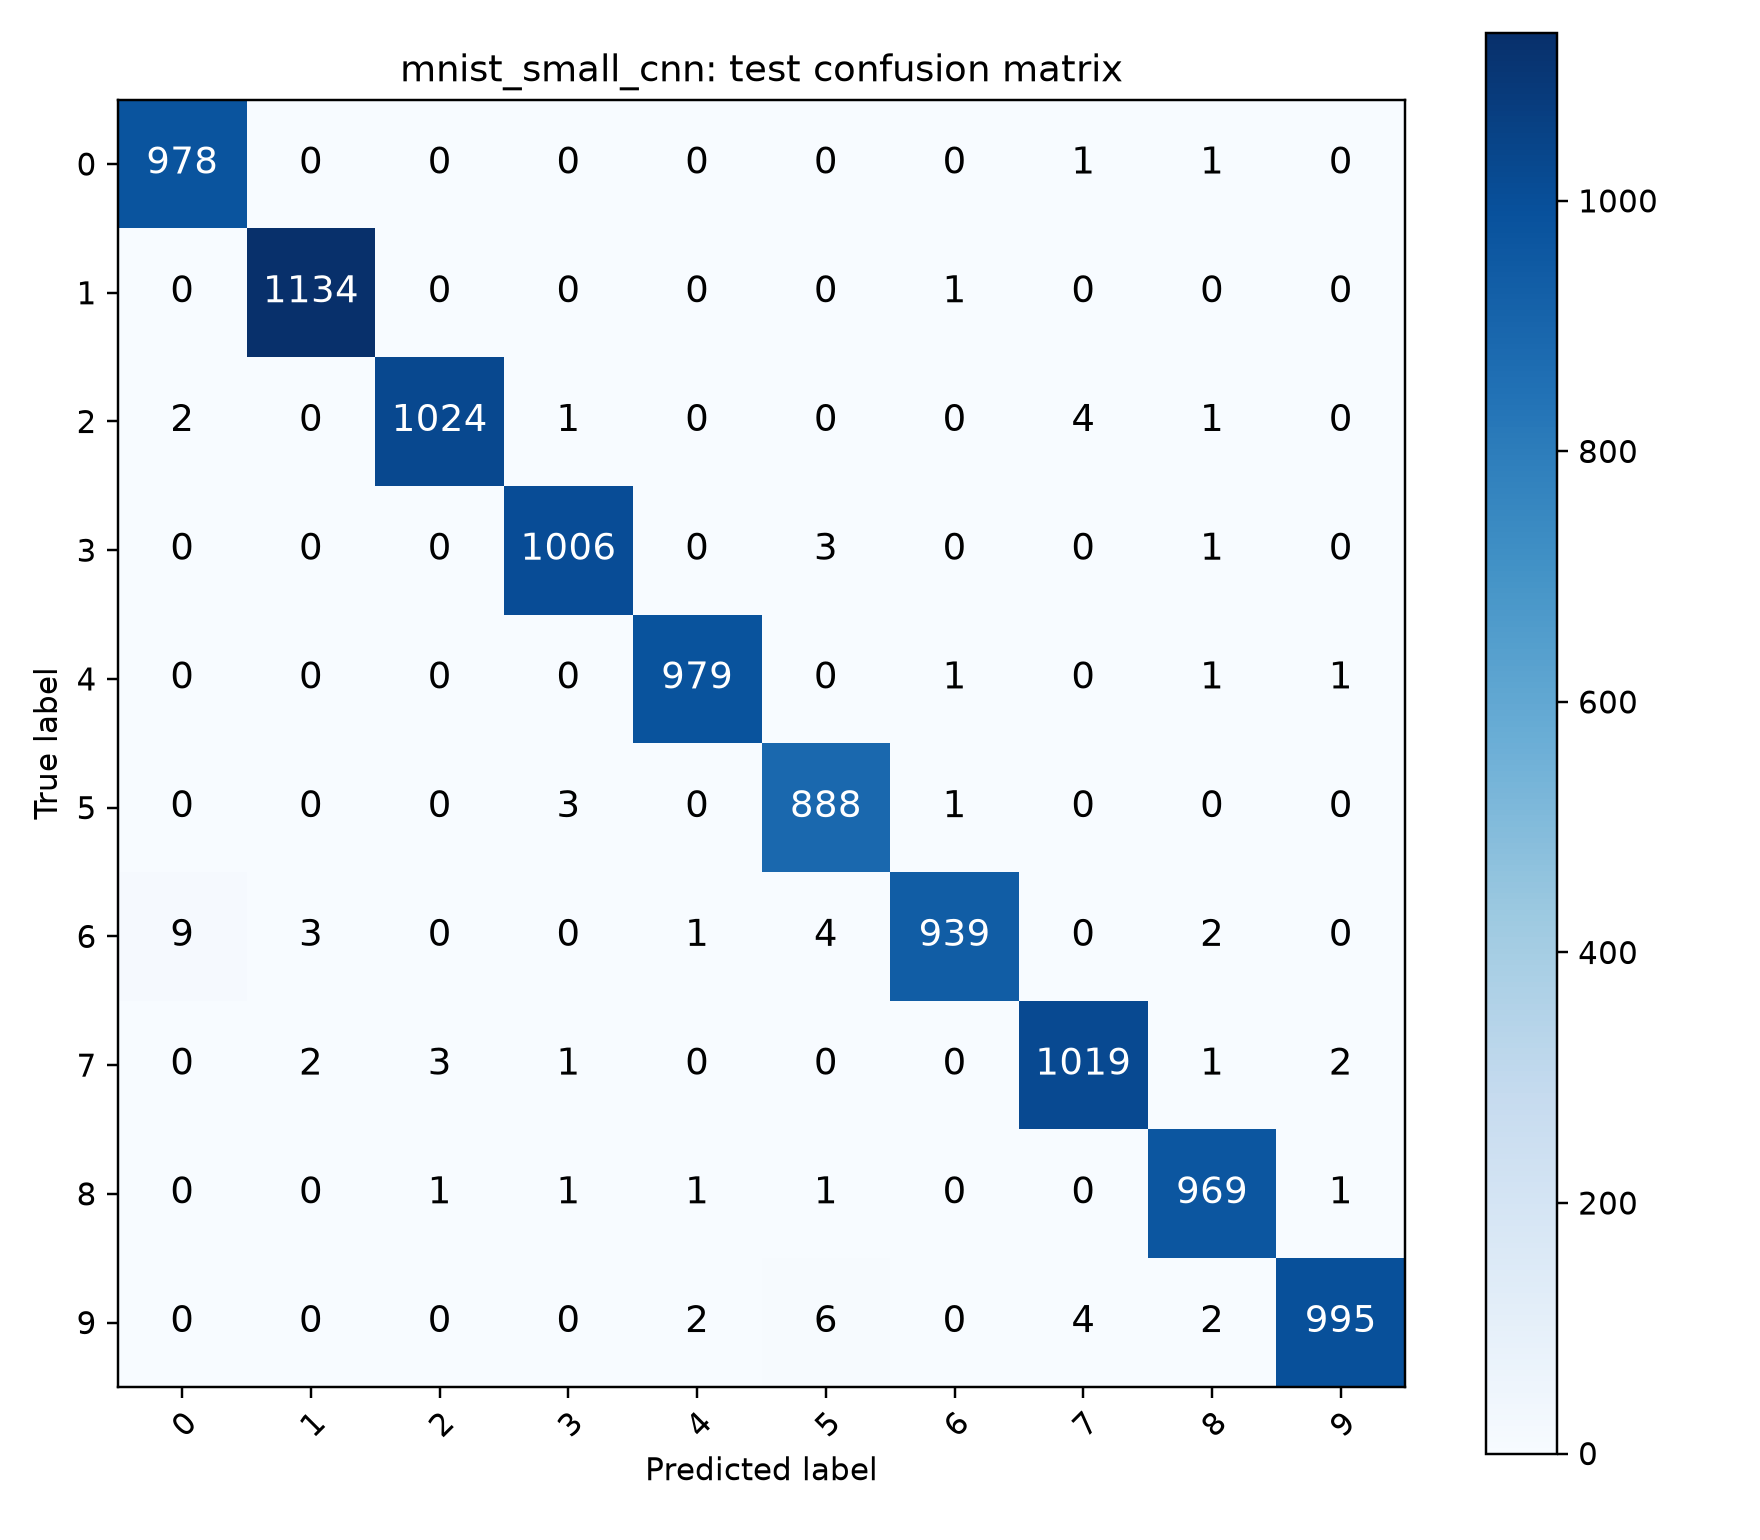

In [4]:
if RUN_TRAINING:
    run_module("src.mnist.train", "--epochs", "10", "--data", str(PROJECT_ROOT / "data"))

show_grid([
    (PROJECT_ROOT / "outputs/figures/mnist_lenet5_learning_curves.png", "LeNet-style learning curves", "curve"),
    (PROJECT_ROOT / "outputs/figures/mnist_small_cnn_learning_curves.png", "Three-layer CNN learning curves", "curve"),
    (PROJECT_ROOT / "outputs/figures/mnist_lenet5_confusion_matrix.png", "LeNet-style test confusion matrix", "matrix"),
    (PROJECT_ROOT / "outputs/figures/mnist_small_cnn_confusion_matrix.png", "Three-layer CNN test confusion matrix", "matrix"),
], "q2-grid")


## Question 3 - ImageNet-pretrained ResNet-18 transfer learning

The tutorial's Hymenoptera `val` split is called the **test set** consistently below (153 images). Both approaches use 10 epochs, batch size 32, SGD with momentum 0.9, and learning rate 0.001. Training augmentation is random resized crop and horizontal flip; both splits use ImageNet normalization.

```python
mean, std = (.485,.456,.406), (.229,.224,.225)
train_tf = transforms.Compose([transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize(mean,std)])
test_tf = transforms.Compose([transforms.Resize((224,224)),
    transforms.ToTensor(), transforms.Normalize(mean,std)])
train = ImageFolder("data/hymenoptera_data/train", transform=train_tf)
test  = ImageFolder("data/hymenoptera_data/val", transform=test_tf)
train_loader = DataLoader(train, batch_size=32, shuffle=True)
test_loader  = DataLoader(test, batch_size=32, shuffle=False)
# fit(..., epochs=10, learning_rate=0.001, device=device)
```

```python
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
if feature_extractor:
    for parameter in model.parameters():
        parameter.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, 2)  # ants and bees
# Fine-tune: optimize every parameter; extractor: optimize model.fc only
```

### Results and discussion

The fine-tuned model classifies 145/153 test images correctly (94.77%); the feature extractor classifies 146/153 (95.42%). A one-image difference is not a meaningful accuracy advantage on this small test set. The feature-extractor setup is substantially more parameter-efficient: 1,026 trainable parameters versus 11,177,538 for fine-tuning. Its BatchNorm running statistics are held fixed during training as well as its convolutional weights. The curves and confusion matrices show the per-run behavior for both approaches.


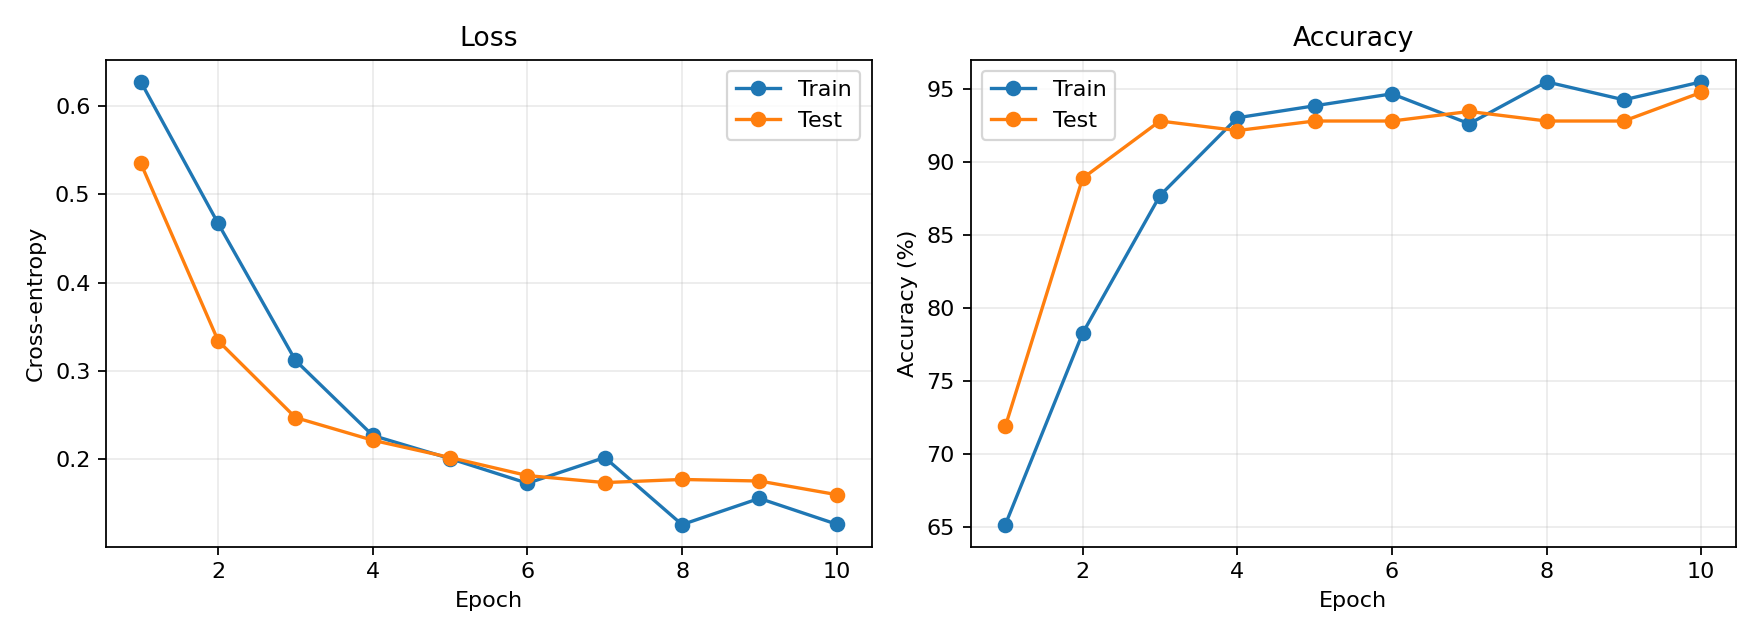
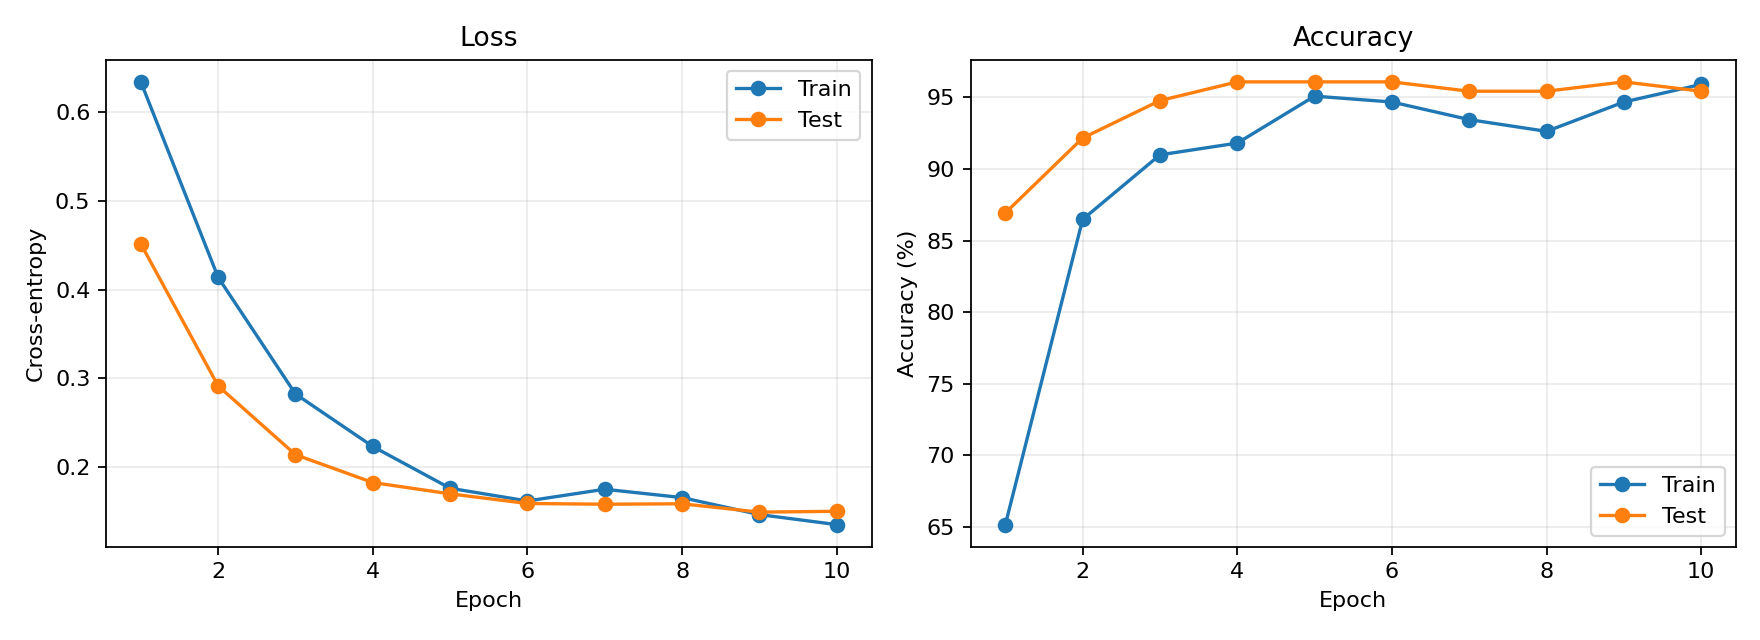
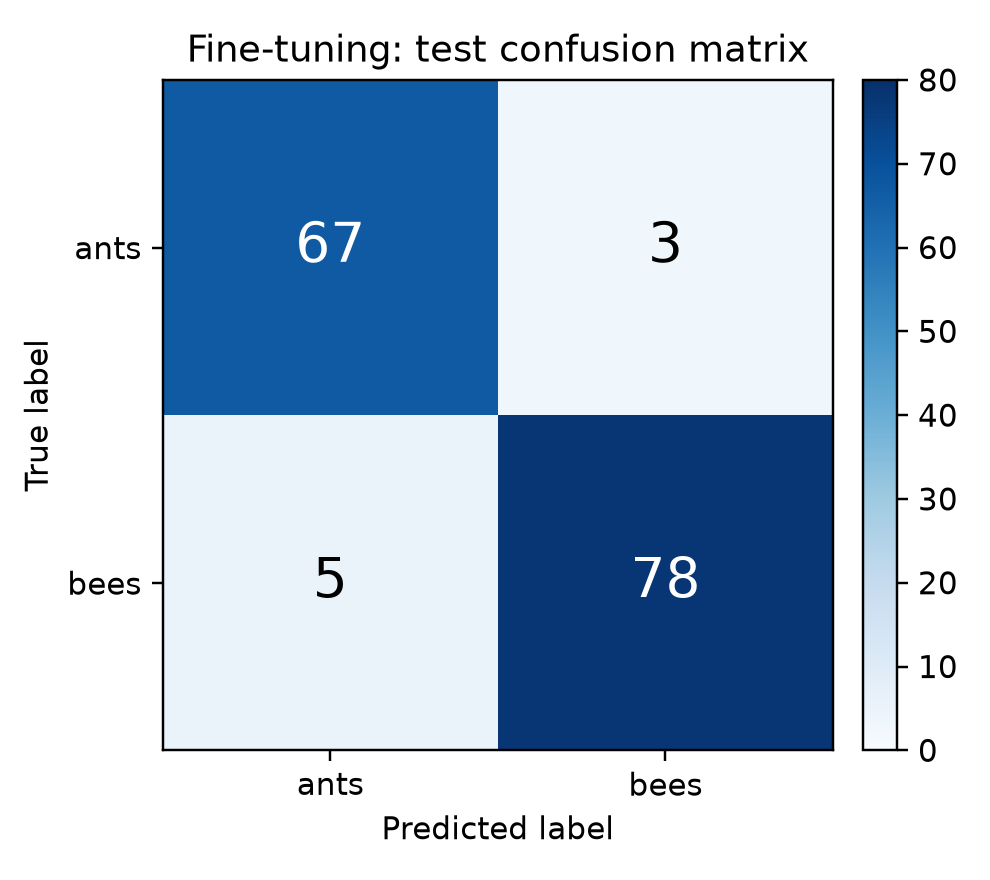
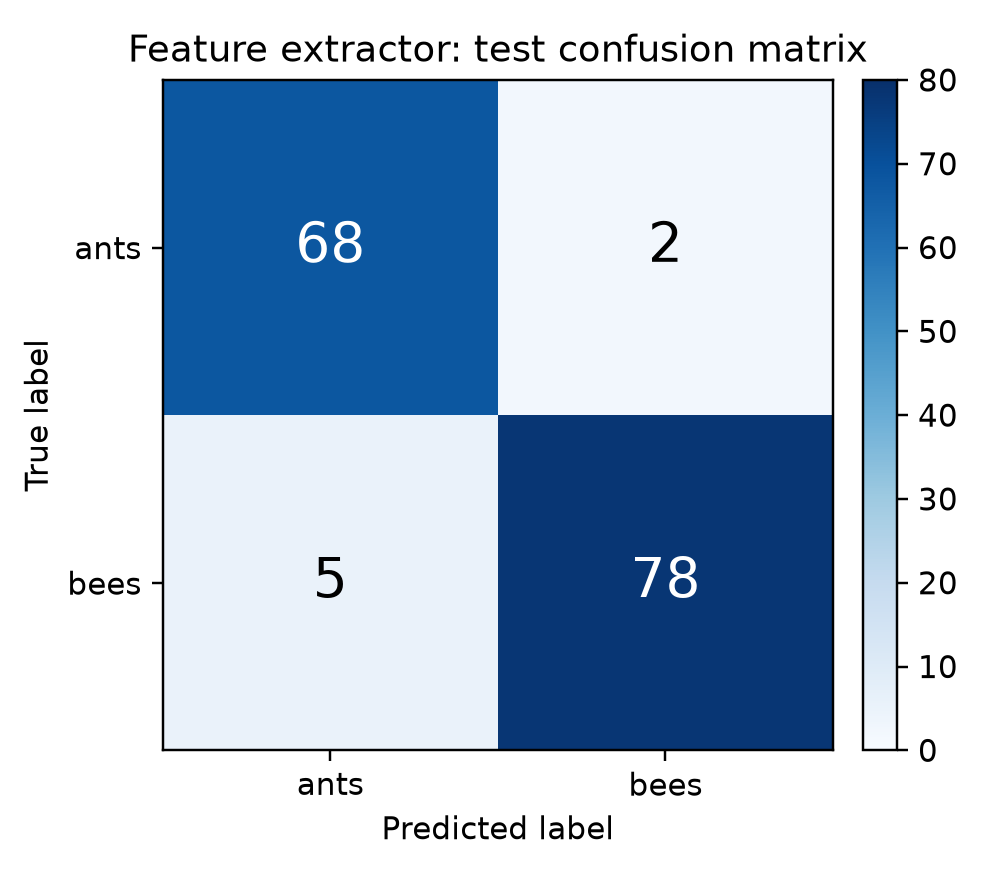

In [5]:
if RUN_TRAINING:
    run_module("src.transfer_learning.train", "--epochs", "10", "--data", str(PROJECT_ROOT / "data"))

show_grid([
    (PROJECT_ROOT / "outputs/figures/hymenoptera_fine_tune_learning_curves.png", "Fine-tuning learning curves", "curve"),
    (PROJECT_ROOT / "outputs/figures/hymenoptera_feature_extractor_learning_curves.png", "Feature-extractor learning curves", "curve"),
    (PROJECT_ROOT / "outputs/figures/hymenoptera_fine_tune_confusion_matrix.png", "Fine-tuning test confusion matrix", "matrix"),
    (PROJECT_ROOT / "outputs/figures/hymenoptera_feature_extractor_confusion_matrix.png", "Feature-extractor test confusion matrix", "matrix"),
], "q3-grid")
